Libraries loaded. Ready to start!
Columns inside the gas dataset:
['date', 'open', 'high', 'low', 'close', 'volume']
My Y target is: close
My X columns are: ['open', 'high', 'low']
Train size: (4784, 3)
Test size: (1196, 3)
Added polynomial and interaction terms successfully!
VIF Check Results:
  Feature Name      VIF Score
5     open low  247713.535509
3       open^2  136542.997933
4    open high  135974.735017
7     high low   99414.341109
8        low^2   55585.526123
6       high^2    7355.783111
0         open    1228.004404
2          low    1000.568151
1         high     837.892946
Train R-squared: 0.9990
Test R-squared:  0.9990
Test RMSE error: 0.0699


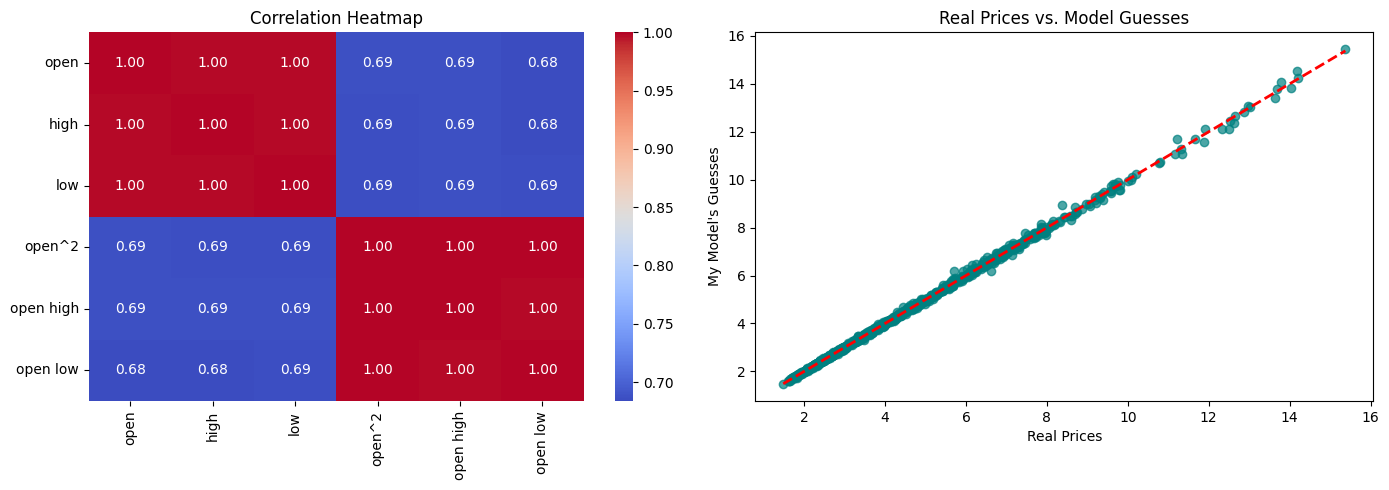

In [1]:
# Step 1: Get the libraries ready for the homework
# pandas and numpy for data tables and math
import pandas as pd
import numpy as np

# matplotlib and seaborn for drawing graphs
import matplotlib.pyplot as plt
import seaborn as sns

# tools from sklearn and statsmodels for regression and checking VIF
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("Libraries loaded. Ready to start!")

# Step 2: Load my datasets from the class GitHub links
link_gas = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/Natural_Gas_data.csv"
link_emissions = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/emissions_high_granularity.csv"
link_accidents = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/dataset2.csv"

# read the csv files into dataframes
df_gas = pd.read_csv(link_gas)
df_emissions = pd.read_csv(link_emissions)
df_accidents = pd.read_csv(link_accidents)

# Let's check the columns in the natural gas data first
print("Columns inside the gas dataset:")
print(df_gas.columns.tolist())

# look at the first few rows
df_gas.head()

# Step 3: Choose the target (y) and features (X)
# I am trying to predict the 'close' price
y_name = 'close'

# Get only number columns so the math doesn't break on text
num_cols = df_gas.select_dtypes(include=[np.number]).columns.tolist()

if y_name in num_cols:
    num_cols.remove(y_name)

# remove rows with missing data (NaNs) so we don't get errors later
clean_df = df_gas[[y_name] + num_cols].dropna()

# I will just pick the first 3 columns for X to make it simple for now
X = clean_df[num_cols[:3]]
y = clean_df[y_name]

print("My Y target is:", y_name)
print("My X columns are:", X.columns.tolist())

# Step 4: Split data into Train and Test
# This helps us check for overfitting by testing on unseen data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

# Step 5: Scale the numbers and add Polynomial features
# Scaling makes all columns fair (no huge numbers dominating).
my_scaler = StandardScaler()
X_train_scaled = my_scaler.fit_transform(X_train)
X_test_scaled = my_scaler.transform(X_test)

# Adding polynomial terms (degree=2) to catch curved patterns in the data
my_poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
X_train_poly = my_poly.fit_transform(X_train_scaled)
X_test_poly = my_poly.transform(X_test_scaled)

# Get the new names for the columns so it is not confusing
poly_names = my_poly.get_feature_names_out(X.columns)
poly_df = pd.DataFrame(X_train_poly, columns=poly_names)

print("Added polynomial and interaction terms successfully!")
poly_df.head(3)

# Step 6: Check for Multicollinearity with VIF
# A high VIF (like over 5) means the columns are too similar and redundant
vif_table = pd.DataFrame()
vif_table["Feature Name"] = poly_df.columns
vif_table["VIF Score"] = [variance_inflation_factor(poly_df.values, i) for i in range(poly_df.shape[1])]

print("VIF Check Results:")
print(vif_table.sort_values(by="VIF Score", ascending=False))

# Step 7: Train the linear regression model and check scores
my_model = LinearRegression()
my_model.fit(X_train_poly, y_train)

# make predictions on both train and test sets
train_guess = my_model.predict(X_train_poly)
test_guess = my_model.predict(X_test_poly)

# calculate R-squared and RMSE
r2_train = r2_score(y_train, train_guess)
r2_test = r2_score(y_test, test_guess)
rmse_test = np.sqrt(mean_squared_error(y_test, test_guess))

print(f"Train R-squared: {r2_train:.4f}")
print(f"Test R-squared:  {r2_test:.4f}")
print(f"Test RMSE error: {rmse_test:.4f}")

# Step 8: Draw the graphs for my milestone report appendix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Heatmap to see correlations
sns.heatmap(poly_df.iloc[:, :6].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0])
axes[0].set_title("Correlation Heatmap")

# Graph 2: Real vs Predicted Prices
axes[1].scatter(y_test, test_guess, alpha=0.7, color="teal")
# drawing a red dashed line to show where perfect guesses would be
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_xlabel("Real Prices")
axes[1].set_ylabel("My Model's Guesses")
axes[1].set_title("Real Prices vs. Model Guesses")

plt.tight_layout()
plt.show()